In [1]:
import pandas as pd

# Load the 4 split files from Day 5 in one go (no copy-pasted lines)
splits = {name: pd.read_parquet(f"../data/processed/{name}.parquet")
          for name in ["train", "val", "test", "test_dedup"]}

for name, part in splits.items():
    print(name, part.shape)


train (367414, 5)
val (142407, 5)
test (169189, 5)
test_dedup (87091, 5)


In [2]:
import sys
sys.path.append("..")
from src.text import clean_text   # single source of truth: src/text.py


In [ ]:
# Expected: 'i was charged twice'
print(repr(clean_text("I was CHARGED Twice")))

# Expected: 'too many spaces'
print(repr(clean_text("  too    many\n\nspaces  ")))

# Tricky: only spaces. Expected: ''
print(repr(clean_text("     ")))

# Not text. Expected: ''
print(repr(clean_text(None)))


'i was charged twice'
'too many spaces'
''
''


: 

In [15]:
n = splits["train"]["Consumer complaint narrative"]
print(n.str.contains(r"XX/XX/\d{4}").sum())


31717


In [17]:
sample = n.sample(5,random_state=42)
for text in sample:
    print("Before",text[:300])
    print("After ",clean_text(text)[:300])
    print("-"*40)

Before I would like to express my deep frustration with the repeated attempts to correct the status of several open accounts that have been erroneously marked as late. Despite my diligent efforts to rectify this issue, it persists, causing significant inconvenience and adversely impacting my creditworthine
After  i would like to express my deep frustration with the repeated attempts to correct the status of several open accounts that have been erroneously marked as late. despite my diligent efforts to rectify this issue, it persists, causing significant inconvenience and adversely impacting my creditworthine
----------------------------------------
Before In accordance with the Fair Credit Reporting act. The List of accounts below has violated my federally protected consumer rights to privacy and confidentiality under 15 USC 1681. 

Account Name : XXXX XXXX Account Number : XXXX Account Name : XXXX Account Number : XXXX Account Name : XXXX Account Nu
After  in accordance with the fair 

In [19]:
import time

N = "Consumer complaint narrative"
start = time.perf_counter()                       # ⏱️ start the stopwatch

for name, part in splits.items():
    part["text_clean"] = part[N].map(clean_text)      # run the machine on each row

total_seconds = time.perf_counter() - start      # ⏱️ stop: now minus start
total_rows = sum(len(part) for part in splits.values())

print(f"Total time: {total_seconds:.1f} s")
print(f"Per ticket: {total_seconds / total_rows * 1000:.3f} ms")

for name, part in splits.items():
    print(name, "empty:", (part["text_clean"] == "").sum())


Total time: 88.3 s
Per ticket: 0.115 ms
train empty: 0
val empty: 0
test empty: 0
test_dedup empty: 0


## Subtask 6: Term frequency by hand

D1: card charged twice card (4 words) · D2: mortgage payment late (3) · D3: card payment declined (3)

| Word | D1 | D2 | D3 |
|---|---|---|---|
| card | 2/4 | 0 | 1/3 |
| charged | 1/4 | 0 | 0 |
| twice | 1/4 | 0 | 0 |
| mortgage | 0 | 1/3 | 0 |
| payment | 0 | 1/3 | 1/3 |
| late | 0 | 1/3 | 0 |
| declined | 0 | 0 | 1/3 |


## Subtask 7: IDF by hand

IDF(word) = ln(N ÷ df), with N = 3 documents

| Word | df | IDF |
|---|---|---|
| card | 2 | 0.405 |
| charged | 1 | 1.099 |
| twice | 1 | 1.099 |
| mortgage | 1 | 1.099 |
| payment | 2 | 0.405 |
| late | 1 | 1.099 |
| declined | 1 | 1.099 |

**1. A word in all 3 documents:** IDF = ln(3/3) = ln(1) = 0. Since TF-IDF = TF × IDF, its weight becomes 0, so the model ignores it. A word that appears everywhere can't tell documents apart.

**2. `redactedinfo` (≈62% of narratives):** IDF ≈ ln(1 / 0.62) ≈ 0.48, close to "card"/"payment" (0.405) and far below rare words (1.099). So yes, the Day 3 statement was correct: IDF down-weights it, but doesn't remove it completely.


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

docs = ["card charged twice card", "mortgage payment late", "card payment declined"]

vec = TfidfVectorizer()
X = vec.fit_transform(docs)
pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(), index=["D1", "D2", "D3"]).round(3)


,card,charged,declined,late,mortgage,payment,twice
D1,0.732,0.481,0.000,0.000,0.000,0.000,0.481
D2,0.000,0.000,0.000,0.623,0.623,0.474,0.000
D3,0.518,0.000,0.681,0.000,0.000,0.518,0.000


In [21]:
import math
math.exp(2.0)

7.38905609893065

In [24]:
math.exp(0.0)/(math.exp(2.0)+math.exp(1.0)+math.exp(0.0))

0.09003057317038046

## Day 7, Subtask 1: Softmax by hand

| Class | Score | e^score | Probability |
|---|---|---|---|
| Credit reporting | 2.0 | 7.389 | 7.389 / 11.107 = **0.665** |
| Debt collection | 1.0 | 2.718 | 2.718 / 11.107 = **0.245** |
| Mortgage | 0.0 | 1.000 | 1.000 / 11.107 = **0.090** |
| **Total** | | **11.107** | **1.000** ✅ |

**If every score increases by 10 (12, 11, 10):** the probabilities don't change. e^(score + 10) = e^10 × e^score, so every slice and the total are multiplied by the same e^10, which cancels out. Softmax only cares about the **differences** between scores, not their absolute size.


## Day 7, Subtask 2: Cross-entropy by hand

loss = −ln(probability given to the true class)

| Case | True class | p(true) | Loss |
|---|---|---|---|
| A | Credit reporting | 0.665 | **0.408** |
| B | Mortgage | 0.090 | **2.408** |
| C | (other complaint) | 0.001 | **6.908** |

**1. Confidently wrong predictions:** the loss grows very fast as p(true) approaches 0. B → C is almost 3× the loss, so confidently wrong predictions are punished much harder than unsure ones.

**2. Class weights (≈30 vs ≈0.13):** a mistake on Debt or credit management counts about 230× more than a mistake on Credit reporting, so the model can't just ignore the small classes and predict the majority. It has to learn them.


In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
import time


In [26]:
vec = TfidfVectorizer()
start = time.perf_counter()# ⏱️ start the stopwatch
X_train = vec.fit_transform(splits['train']['text_clean'])
fit_seconds = time.perf_counter() - start# ⏱️ stop: now minus start


X_val = vec.transform(splits['val']['text_clean'])

print("Vocabulary size:", len(vec.get_feature_names_out()))
print("train Matrix shape:", X_train.shape)
print("val Matrix shape:", X_val.shape)
print(f"Fit time: {fit_seconds:.1f} s")

Vocabulary size: 80578
train Matrix shape: (367414, 80578)
val Matrix shape: (142407, 80578)
Fit time: 75.4 s


In [28]:
import numpy as np
doc_freq = np.asarray((X_train > 0).sum(axis=0)).ravel()
print((doc_freq < 5).sum(), (doc_freq < 5).mean())


55839 0.6929807143389014


In [29]:
from sklearn.linear_model import LogisticRegression

In [32]:
# 1. Config A vectoriser: fit on train, transform val
vec = TfidfVectorizer(min_df=5, ngram_range=(1, 2), sublinear_tf=True)
X_train = vec.fit_transform(splits["train"]["text_clean"])
X_val = vec.transform(splits["val"]["text_clean"])
y_train = splits["train"]["label"]
print("Features:", X_train.shape[1])


Features: 479177


In [33]:
# 2. Train and time it
model = LogisticRegression(max_iter=1000)
start = time.perf_counter()
model.fit(X_train, y_train)
train_seconds = time.perf_counter() - start


In [35]:
print("coef_ shape:", model.coef_.shape)
print(f"Training time: {train_seconds / 60:.1f} min")

coef_ shape: (11, 479177)
Training time: 20.0 min


In [37]:
from sklearn.metrics import classification_report

y_val = splits["val"]["label"]
y_pred = model.predict(X_val)

print(classification_report(y_val, y_pred, digits=3))

                                                         precision    recall  f1-score   support

                            Checking or savings account      0.824     0.903     0.862      9148
                                            Credit card      0.723     0.658     0.689      3801
    Credit reporting or other personal consumer reports      0.938     0.977     0.957     91690
                                        Debt collection      0.722     0.590     0.649      8124
                              Debt or credit management      0.675     0.075     0.136       358
     Money transfer, virtual currency, or money service      0.979     0.916     0.947     24817
                                               Mortgage      0.862     0.840     0.851      1260
Payday loan, title loan, personal loan, or advance loan      0.634     0.371     0.468       593
                                           Prepaid card      0.747     0.470     0.577       402
                             

In [38]:
# Keep the first model's predictions: y_pred (no weights)
model_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
start = time.perf_counter()
model_bal.fit(X_train, y_train)
print(f"Training time: {(time.perf_counter() - start) / 60:.1f} min")

y_pred_bal = model_bal.predict(X_val)


Training time: 19.3 min


In [39]:
cols = ["precision", "recall", "f1-score"]
rep_nw  = pd.DataFrame(classification_report(y_val, y_pred,     output_dict=True)).T[cols]
rep_bal = pd.DataFrame(classification_report(y_val, y_pred_bal, output_dict=True)).T[cols]

side = pd.concat([rep_nw, rep_bal], axis=1, keys=["no_weights", "balanced"]).round(3)
side


no_weights                  \
                                                    precision recall f1-score   
Checking or savings account                             0.824  0.903    0.862   
Credit card                                             0.723  0.658    0.689   
Credit reporting or other personal consumer rep...      0.938  0.977    0.957   
Debt collection                                         0.722  0.590    0.649   
Debt or credit management                               0.675  0.075    0.136   
Money transfer, virtual currency, or money service      0.979  0.916    0.947   
Mortgage                                                0.862  0.840    0.851   
Payday loan, title loan, personal loan, or adva...      0.634  0.371    0.468   
Prepaid card                                            0.747  0.470    0.577   
Student loan                                            0.899  0.684    0.777   
Vehicle loan or lease                                   0.749  0.551    0.635   
accuracy                                                0.918  0.918    0.918   
macro avg                                               0.796  0.640    0.686   
weighted avg                                            0.915  0.918    0.914   

                                                    balanced                  
                                                   precision recall f1-score  
Checking or savings account                            0.842  0.883    0.862  
Credit card                                            0.524  0.707    0.602  
Credit reporting or other personal consumer rep...     0.973  0.856    0.911  
Debt collection                                        0.395  0.751    0.518  
Debt or credit management                              0.276  0.355    0.311  
Money transfer, virtual currency, or money service     0.964  0.953    0.959  
Mortgage                                               0.747  0.899    0.816  
Payday loan, title loan, personal loan, or adva...     0.368  0.669    0.475  
Prepaid card                                           0.475  0.652    0.550  
Student loan                                           0.668  0.876    0.758  
Vehicle loan or lease                                  0.420  0.777    0.545  
accuracy                                               0.862  0.862    0.862  
macro avg                                              0.605  0.762    0.664  
weighted avg                                           0.904  0.862    0.876

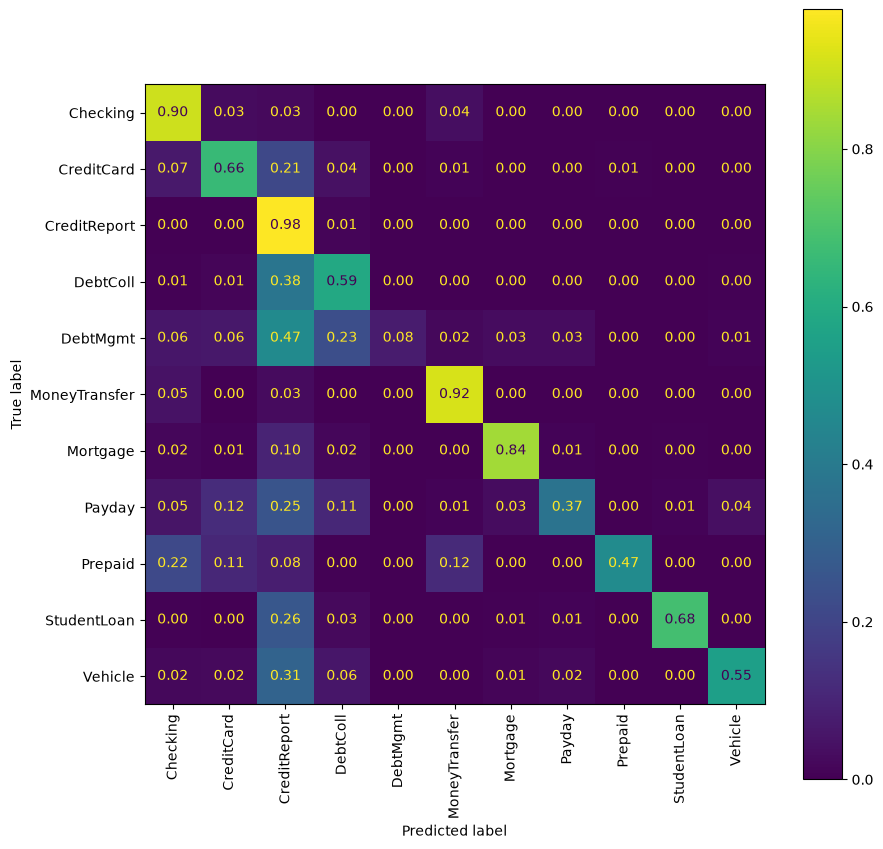

In [40]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

SHORT = {
    "Checking or savings account": "Checking",
    "Credit card": "CreditCard",
    "Credit reporting or other personal consumer reports": "CreditReport",
    "Debt collection": "DebtColl",
    "Debt or credit management": "DebtMgmt",
    "Money transfer, virtual currency, or money service": "MoneyTransfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday",
    "Prepaid card": "Prepaid",
    "Student loan": "StudentLoan",
    "Vehicle loan or lease": "Vehicle",
}

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    y_val.map(SHORT), pd.Series(y_pred).map(SHORT),
    normalize="true", values_format=".2f", xticks_rotation=90, ax=ax,
)
plt.show()


In [41]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

# Config B: unigrams only
vec_b = TfidfVectorizer(min_df=5, ngram_range=(1, 1), sublinear_tf=True)
Xb_train = vec_b.fit_transform(splits["train"]["text_clean"])
Xb_val = vec_b.transform(splits["val"]["text_clean"])

# Soft weights = square root of balanced
w = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
soft = dict(zip(np.unique(y_train), np.sqrt(w)))

# Config A rows (already trained earlier)
results = [
    {"config": "A-none", "features": X_train.shape[1], "train_min": 20.0,
     "val_acc": accuracy_score(y_val, y_pred), "val_macro_f1": f1_score(y_val, y_pred, average="macro")},
    {"config": "A-balanced", "features": X_train.shape[1], "train_min": 19.3,
     "val_acc": accuracy_score(y_val, y_pred_bal), "val_macro_f1": f1_score(y_val, y_pred_bal, average="macro")},
]

# Config B: 3 weight settings
for name, cw in [("B-none", None), ("B-balanced", "balanced"), ("B-soft", soft)]:
    m = LogisticRegression(max_iter=1000, class_weight=cw)
    start = time.perf_counter()
    m.fit(Xb_train, y_train)
    minutes = (time.perf_counter() - start) / 60
    p = m.predict(Xb_val)
    results.append({"config": name, "features": Xb_train.shape[1], "train_min": minutes,
                    "val_acc": accuracy_score(y_val, p), "val_macro_f1": f1_score(y_val, p, average="macro")})

pd.DataFrame(results).round(3)


,config,features,train_min,val_acc,val_macro_f1
0,A-none,479177,20.000,0.918,0.686
1,A-balanced,479177,19.300,0.862,0.664
2,B-none,24739,3.006,0.916,0.696
3,B-balanced,24739,3.645,0.830,0.602
4,B-soft,24739,32.444,0.894,0.691


In [42]:
import joblib, os, sklearn

vec_b_loaded = joblib.load("../models/tfidf_b.joblib")
model_b_loaded = joblib.load("../models/logreg_b.joblib")

X5 = vec_b_loaded.transform(splits["val"]["text_clean"][:5])
print(model_b_loaded.predict(X5))

for f in ["tfidf_b.joblib", "logreg_b.joblib"]:
    print(f, round(os.path.getsize(f"../models/{f}") / 1e6, 2), "MB")
print("scikit-learn", sklearn.__version__)


['Credit reporting or other personal consumer reports'
 'Credit reporting or other personal consumer reports'
 'Credit reporting or other personal consumer reports'
 'Credit reporting or other personal consumer reports'
 'Money transfer, virtual currency, or money service']
tfidf_b.joblib 0.53 MB
logreg_b.joblib 2.18 MB
scikit-learn 1.9.1


In [44]:
import numpy as np
words = vec_b_loaded.get_feature_names_out()
classes = model_b_loaded.classes_

for i, cls in enumerate(classes):
    row = model_b_loaded.coef_[i]
    top = np.argsort(row)[-10:][::-1]
    print(SHORT[cls], "->", ", ".join(words[top]))

Checking -> bank, account, checking, debit, chime, cd, overdraft, funds, chase, branch
CreditCard -> card, credit, synchrony, citi, capital, discover, comenity, chase, rewards, barclays
CreditReport -> experian, equifax, transunion, credit, report, reporting, redactedinfo, late, inquiries, inquiry
DebtColl -> debt, credit, collection, markings, collections, report, owed, garnishment, threatened, recovery
DebtMgmt -> credit, debt, lexington, score, repair, services, management, settlement, relief, debts
MoneyTransfer -> paypal, venmo, coinbase, money, transfer, wire, cashapp, funds, zelle, transaction
Mortgage -> mortgage, escrow, heloc, home, modification, loan, foreclosure, property, appraisal, house
Payday -> loan, line, affirm, main, onemain, titlemax, klarna, finance, personal, borrowed
Prepaid -> card, prepaid, gift, netspend, network, unemployment, amex, benefits, express, cards
StudentLoan -> mohela, nelnet, navient, edfinancial, aidvantage, loans, student, loan, school, educati

In [49]:
# Predictions from the chosen baseline (B-none)
X_val_b = vec_b_loaded.transform(splits["val"]["text_clean"])
pred_b = model_b_loaded.predict(X_val_b)

val_check = pd.DataFrame({
    "text": splits["val"]["text_clean"].values,
    "true": splits["val"]["label"].values,
    "pred": pred_b,
})

mask = (val_check["true"] == "Debt collection") & (val_check["pred"] == "Credit reporting or other personal consumer reports")
errors = val_check[mask]
print("How many:", len(errors))

for i, text in enumerate(errors["text"].sample(10, random_state=42), start=1):
    print(f"--- {i} ---")
    print(text[:300])


How many: 3418
--- 1 ---
redactedinfo redactedinfo redactedinfo redactedinfo redactedinfo redactedinfo redactedinfo redactedinfo redactedinfo redactedinfo redactedinfo redactedinfo / redactedinfo /year> to whom it may concern subject : formal complaint and legal grievance regarding consumer compliance practices dear sir/mad
--- 2 ---
after reviewing my credit report, i discovered accounts that i did not recognize or apply for upon further investigation. i realized that my personal information was exposed in several data breaches as well. i have no recollection of applying to any of these accounts at question and that and negativ
--- 3 ---
i want to stress that i did not give written permission for these specific transactions to be included in my consumer report. at no point did i authorize these entries, and their presence on my report is unwarranted. consequently, i am formally requesting that these accounts be blocked and removed f
--- 4 ---
i would like this remove from all credit r

                                                         precision    recall  f1-score   support

                            Checking or savings account      0.826     0.898     0.860      9148
                                            Credit card      0.690     0.644     0.666      3801
    Credit reporting or other personal consumer reports      0.939     0.973     0.956     91690
                                        Debt collection      0.694     0.545     0.610      8124
                              Debt or credit management      0.741     0.176     0.284       358
     Money transfer, virtual currency, or money service      0.977     0.929     0.952     24817
                                               Mortgage      0.871     0.850     0.860      1260
Payday loan, title loan, personal loan, or advance loan      0.595     0.427     0.497       593
                                           Prepaid card      0.631     0.480     0.545       402
                             

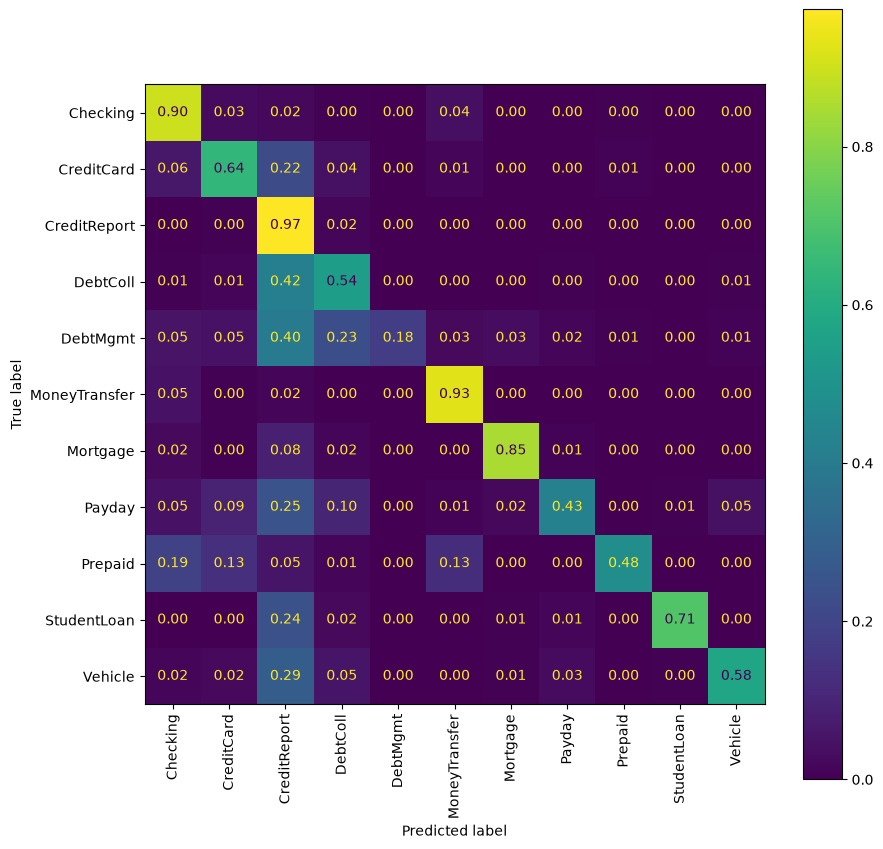

In [50]:
X_val_b = vec_b_loaded.transform(splits["val"]["text_clean"])
pred_b = model_b_loaded.predict(X_val_b)
print(classification_report(splits["val"]["label"], pred_b, digits=3))

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    splits["val"]["label"].map(SHORT), pd.Series(pred_b).map(SHORT),
    normalize="true", values_format=".2f", xticks_rotation=90, ax=ax)
plt.show()


In [51]:
D = "Debt or credit management"
val_check = pd.DataFrame({"text": splits["val"]["text_clean"].values,
                          "true": splits["val"]["label"].values, "pred": pred_b})
errors = val_check[(val_check["true"] == D) & (val_check["pred"] != D)]
print("Misrouted:", len(errors), "of", (val_check["true"] == D).sum())

for i, (_, row) in enumerate(errors.sample(10, random_state=42).iterrows(), start=1):
    print(f"--- {i} → {SHORT[row['pred']]} ---")
    print(row["text"][:300])


Misrouted: 295 of 358
--- 1 → CreditReport ---
equifax failed in its basic duty to investigate and resolve consumer disputes about inaccurate information on their credit reports, causing significant financial loss and even causing homelessness. due to the disputed items on my report not being removed when they should have been due to fraud, my c
--- 2 → DebtColl ---
i received a mail redactedinfo version of advertisement from a company offering debt settlement services. i did not request to receive such advertisements. the advertisement mainly promoted " saving you money immediately '' and " reducing high interest rates. '' i do not want to receive these types 
--- 3 → DebtColl ---
i was given a speech over the phone that made it sound so good to be debt free. i was being bothered at my part time job from credit 9 through phone calls pressuring me to sign the paperwork that they had sent to me through my e-mail. i only had a short time to sign. i replied to the e-mail i was at
--- 4 → 

In [52]:
proba = model_b_loaded.predict_proba(X_val_b)     # 11 probabilities per ticket
conf = proba.max(axis=1)                # the biggest slice per row


In [53]:
correct = (pred_b == splits["val"]["label"].values)


In [54]:
print("Median conf (correct):", np.median(conf[correct]))
print("Median conf (wrong):  ", np.median(conf[~correct]))

Median conf (correct): 0.9544785159461601
Median conf (wrong):   0.6392010652722635


In [55]:
for t in [0.5, 0.6, 0.7]:
    review = conf < t                          # unsure tickets go to a human
    pct_review = review.mean() * 100                # % of ALL tickets sent to review
    pct_caught = (review & ~correct).sum() / (~correct).sum() * 100   # % of errors caught
    print(f"threshold {t}: review {pct_review:.1f}% | errors caught {pct_caught:.1f}%")


threshold 0.5: review 5.6% | errors caught 28.0%
threshold 0.6: review 14.6% | errors caught 44.5%
threshold 0.7: review 27.4% | errors caught 60.4%
